# 00 — Catálogo y Banco Visual de Cartas de Clash Royale (Cloudflare R2)

Este notebook verifica (y sincroniza si faltase algún archivo) el **banco canónico de cartas** en Cloudflare R2:
- **Manifiesto maestro:** `s3://cr-videos/metadata/cards_catalog.json`
- **Imágenes PNG (`150x180` RGBA):** `s3://cr-videos/assets/cards/<key>.png` (servidas también en `https://cdn-cr.eddux.dev/assets/cards/<key>.png`)

### Propósito en el Pipeline
En el **Notebook 03 (Extracción de Jugadas)**, cuando detectamos una caída de elixir y la rotación de un slot en la mano del jugador, recortamos el slot en $t_{\text{drop}} - 0.8\text{ s}$ y lo comparamos contra este banco (filtrando además por el coste de elixir) para obtener el nombre exacto de la carta en español.

In [3]:
import os, sys, json, time
from io import BytesIO
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import requests
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import boto3
from botocore.config import Config

# 1. Directorios de trabajo (compatible con Kaggle y entorno local)
WORK_DIR = Path('/kaggle/working') if Path('/kaggle').exists() else Path('./working')
CARDS_DIR = WORK_DIR / 'cards_cache'
CARDS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Carga de credenciales desde Kaggle Secrets o .env local
for env_candidate in [Path('.env'), Path('../.env')]:
    if env_candidate.exists():
        for line in env_candidate.read_text().splitlines():
            line = line.strip()
            if line and not line.startswith('#') and '=' in line:
                k, v = line.split('=', 1)
                os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

def get_config(key: str, default: str = None) -> str:
    if os.getenv(key):
        return os.getenv(key)
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(key)
    except Exception:
        return default

R2_ENDPOINT = get_config('R2_ENDPOINT')
R2_ACCESS_KEY = get_config('R2_ACCESS_KEY')
R2_SECRET_KEY = get_config('R2_SECRET_KEY')
R2_BUCKET = get_config('R2_BUCKET', 'cr-videos')
CDN_BASE = get_config('CDN_URL', 'https://cdn-cr.eddux.dev').rstrip('/')

s3 = boto3.client(
    's3',
    endpoint_url=R2_ENDPOINT,
    aws_access_key_id=R2_ACCESS_KEY,
    aws_secret_access_key=R2_SECRET_KEY,
    config=Config(signature_version='s3v4', max_pool_connections=32)
)
print(f'✔ Conectado a bucket R2: {R2_BUCKET} | CDN: {CDN_BASE}')

✔ Conectado a bucket R2: cr-videos | CDN: https://cdn-cr.eddux.dev


In [4]:
# Lectura del manifiesto metadata/cards_catalog.json desde Cloudflare R2
obj = s3.get_object(Bucket=R2_BUCKET, Key='metadata/cards_catalog.json')
catalog_manifest = json.loads(obj['Body'].read().decode('utf-8'))
cards_dict = catalog_manifest['cards']

std_base = sorted(
    [c for c in cards_dict.values() if c['is_standard_deck_card'] and c['variant'] == 'base'],
    key=lambda x: (x['elixir'], x['name_es'])
)
std_evo = sorted(
    [c for c in cards_dict.values() if c['is_standard_deck_card'] and c['variant'] == 'evolution'],
    key=lambda x: (x['elixir'], x['name_es'])
)
extra_cards = [c for c in cards_dict.values() if not c['is_standard_deck_card']]

print(f"Última actualización en R2 : {catalog_manifest['updated_at']}")
print(f"Total assets en R2         : {catalog_manifest['total_assets']}")
print(f"  • Cartas de mazo (base)  : {len(std_base)}")
print(f"  • Evoluciones (-ev1)     : {len(std_evo)}")
print(f"  • Torres / Eventos / Etc : {len(extra_cards)}")

Última actualización en R2 : 2026-10-16T11:21:01Z
Total assets en R2         : 204
  • Cartas de mazo (base)  : 121
  • Evoluciones (-ev1)     : 39
  • Torres / Eventos / Etc : 44


In [5]:
# Descarga en paralelo de los iconos desde nuestro R2 / CDN hacia caché local para visualización
def fetch_card_icon(card_entry: dict) -> tuple[str, Image.Image]:
    key = card_entry['key']
    local_path = CARDS_DIR / f'{key}.png'
    if not local_path.exists():
        r = requests.get(card_entry['cdn_url'], timeout=15)
        r.raise_for_status()
        local_path.write_bytes(r.content)
    return key, Image.open(local_path).convert('RGBA')

target_cards = std_base + std_evo
icons = {}
t0 = time.time()
with ThreadPoolExecutor(max_workers=24) as pool:
    for k, img in pool.map(fetch_card_icon, target_cards):
        icons[k] = img

print(f'✔ {len(icons)} iconos cargados desde R2/CDN en {time.time() - t0:.2f}s (resolución ejemplo: {next(iter(icons.values())).size})')

✔ 160 iconos cargados desde R2/CDN en 4.45s (resolución ejemplo: (150, 180))


/tmp/ipykernel_114/590245427.py:17: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.985])
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


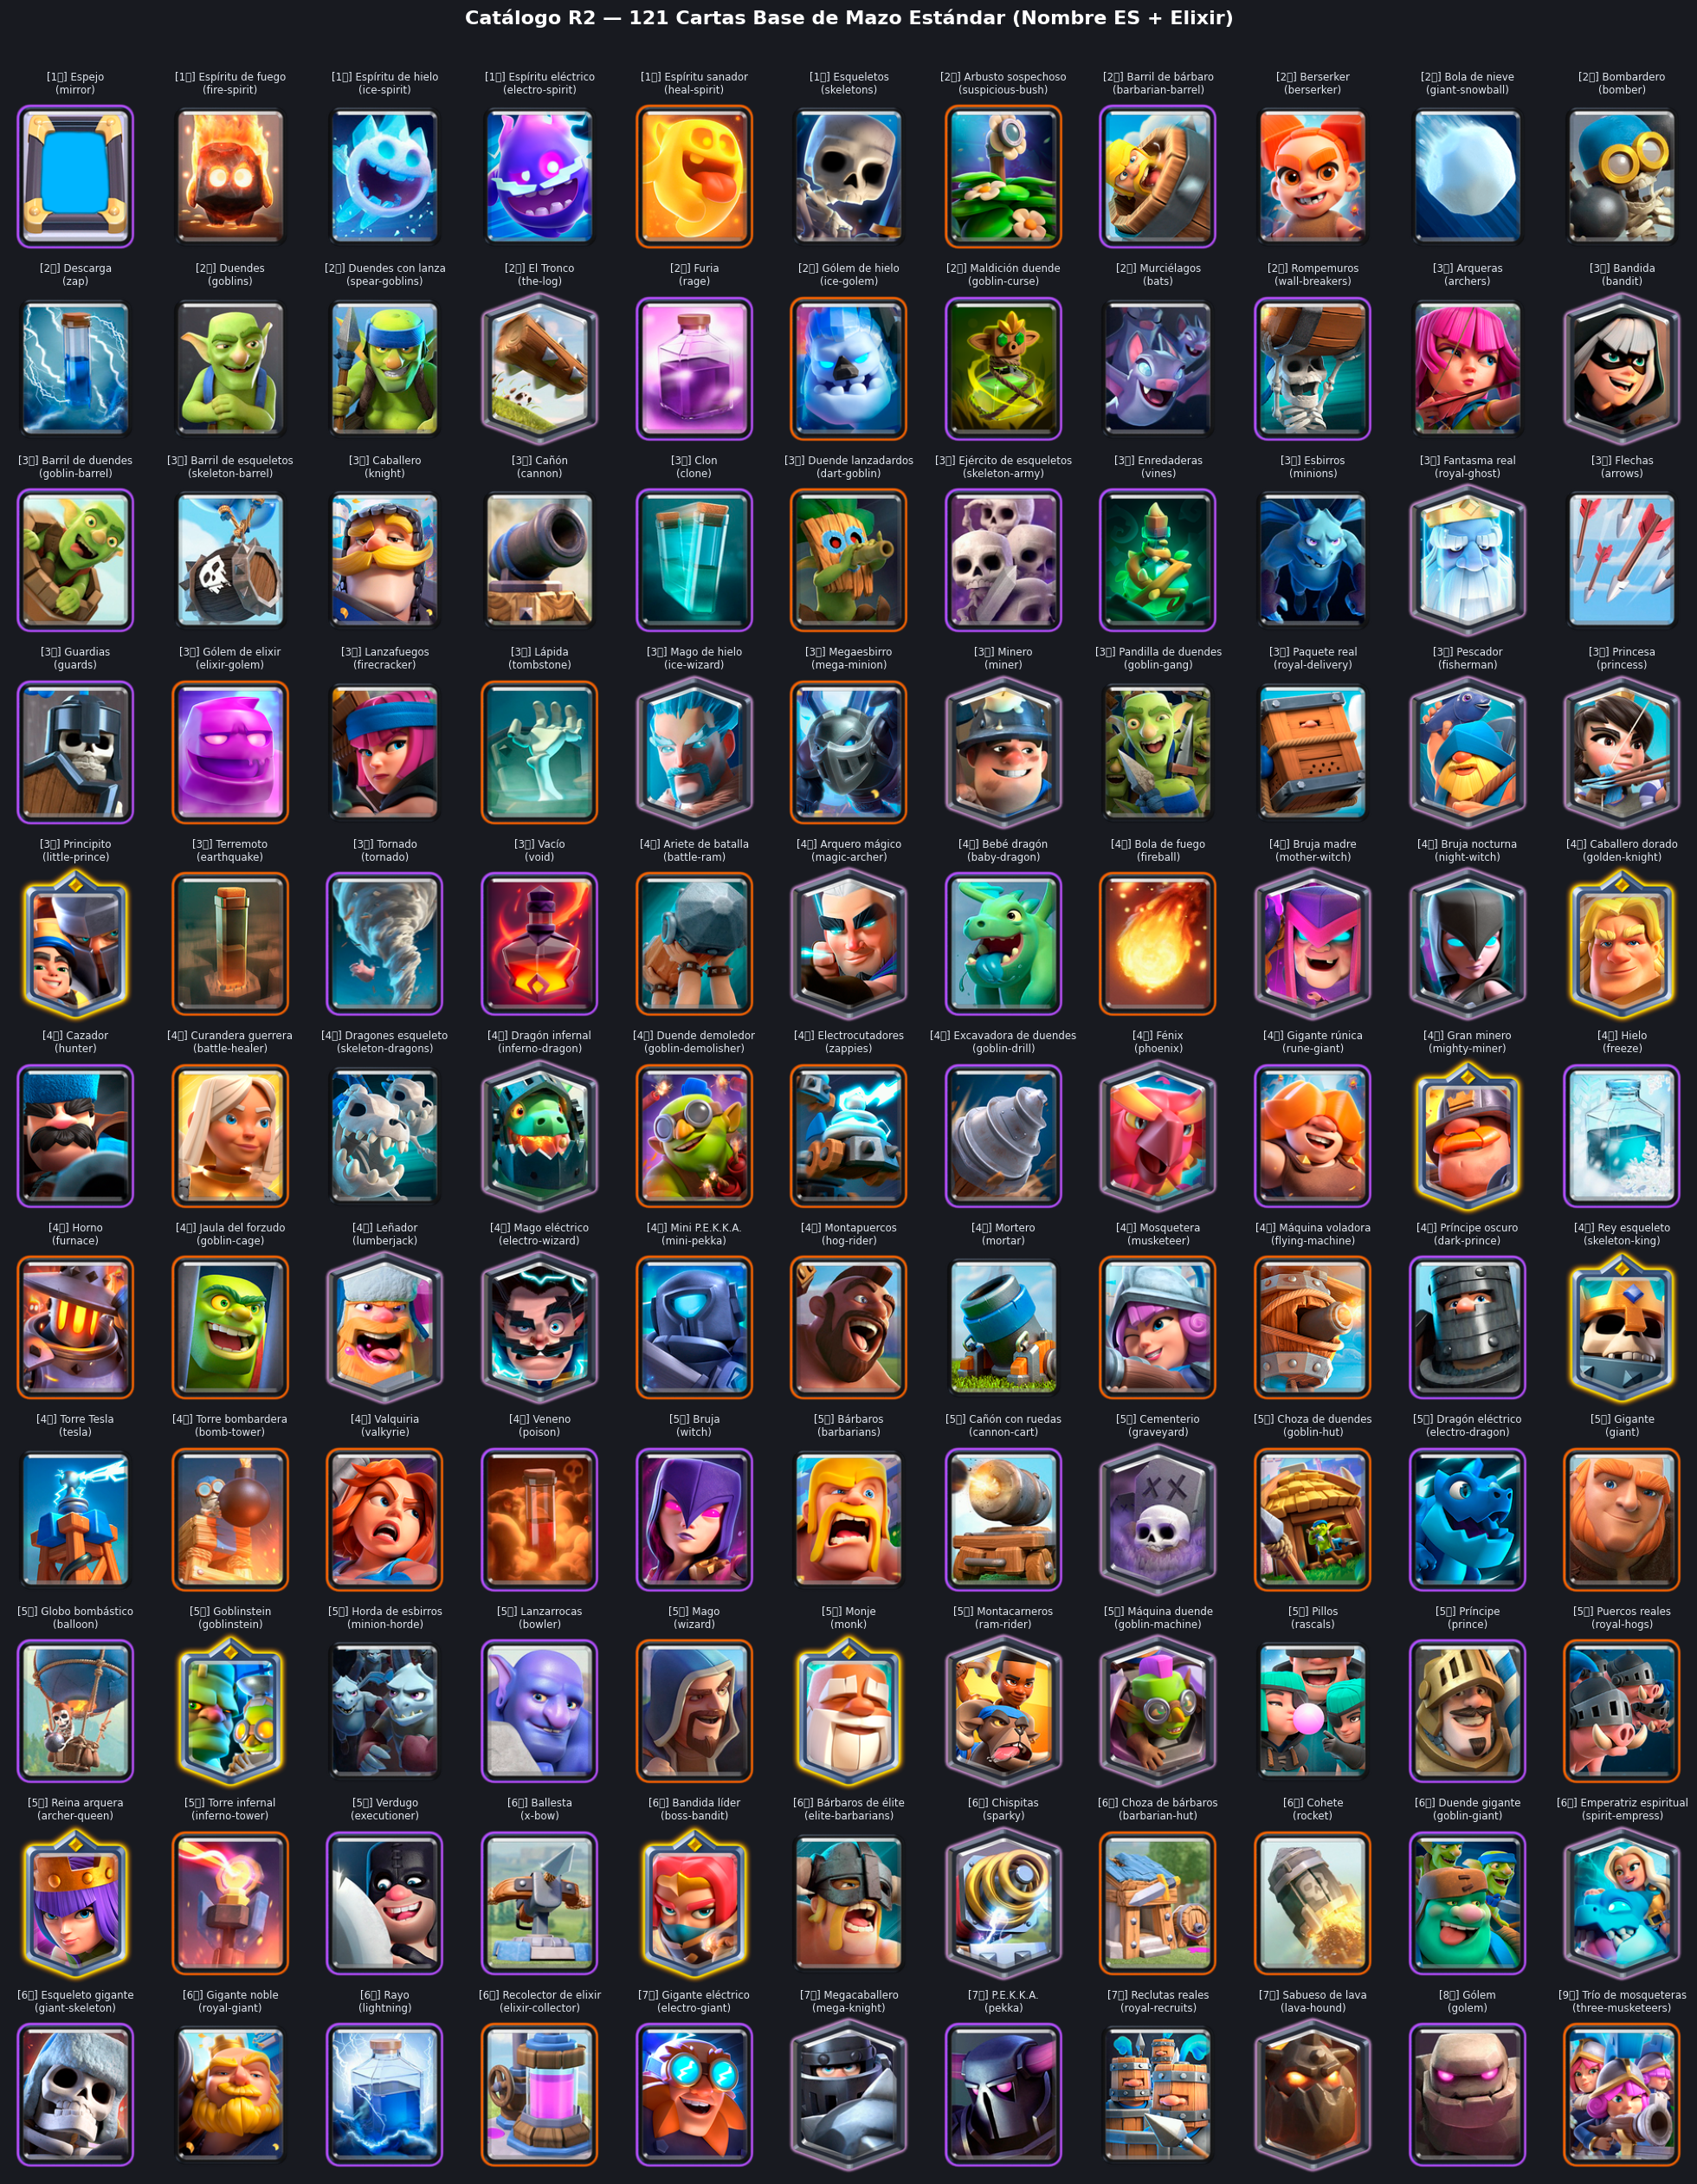

In [ ]:
# =========================================================================
# GALERÍA 1: LAS 121 CARTAS DE MAZO ESTÁNDAR (ORDENADAS POR COSTE DE ELIXIR)
# =========================================================================
cols = 11
rows = int(np.ceil(len(std_base) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.8, rows * 2.3), facecolor='#181a20')
fig.suptitle(f'Catálogo R2 — {len(std_base)} Cartas Base de Mazo Estándar (Nombre ES + Elixir)', color='white', fontsize=16, fontweight='bold', y=0.995)

for idx, ax in enumerate(axes.flat):
    ax.set_facecolor('#181a20')
    ax.axis('off')
    if idx < len(std_base):
        c = std_base[idx]
        ax.imshow(icons[c['key']])
        ax.set_title(f"[{c['elixir']}] {c['name_es']}\n({c['key']})", color='#e2e8f0', fontsize=8.5, pad=3)

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

/tmp/ipykernel_114/270524470.py:17: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.97])


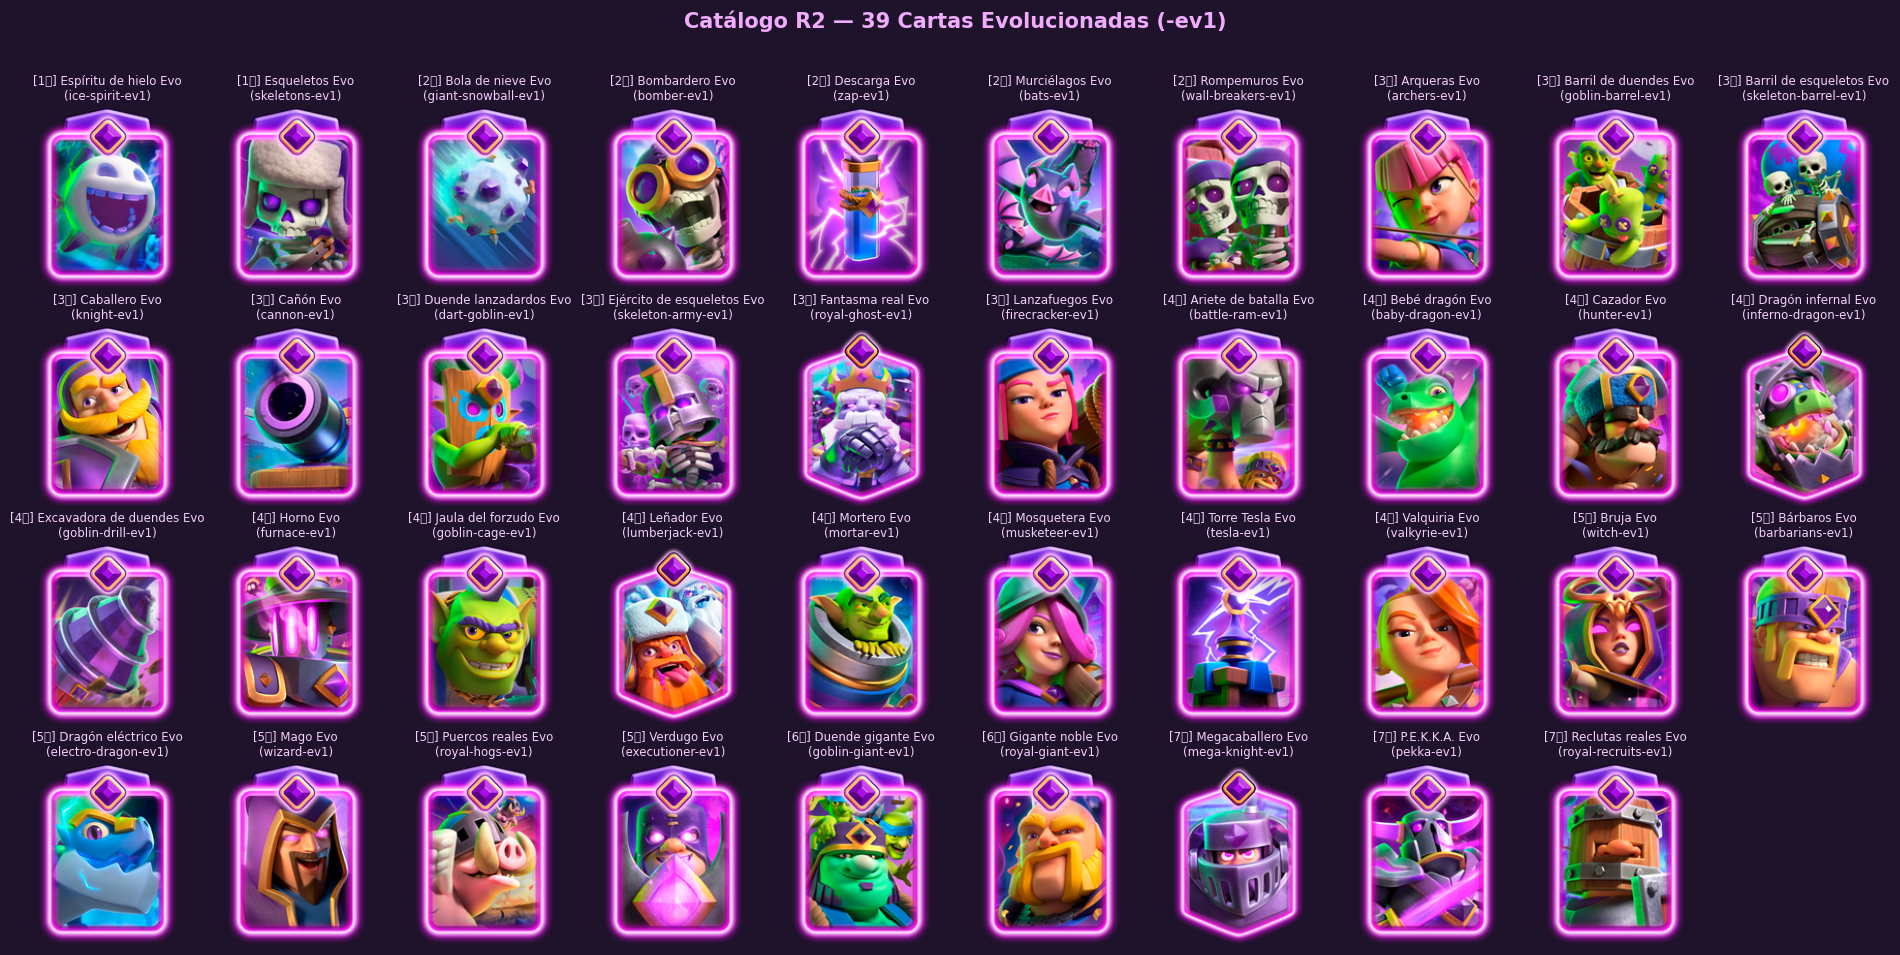

In [7]:
# =========================================================================
# GALERÍA 2: LAS 39 CARTAS EVOLUCIONADAS (-ev1) EN R2
# =========================================================================
cols_evo = 10
rows_evo = int(np.ceil(len(std_evo) / cols_evo))
fig, axes = plt.subplots(rows_evo, cols_evo, figsize=(cols_evo * 1.9, rows_evo * 2.4), facecolor='#1e132a')
fig.suptitle(f'Catálogo R2 — {len(std_evo)} Cartas Evolucionadas (-ev1)', color='#f0abfc', fontsize=15, fontweight='bold', y=0.99)

for idx, ax in enumerate(axes.flat):
    ax.set_facecolor('#1e132a')
    ax.axis('off')
    if idx < len(std_evo):
        c = std_evo[idx]
        ax.imshow(icons[c['key']])
        ax.set_title(f"[{c['elixir']}💧] {c['name_es']} Evo\n({c['key']})", color='#f5d0fe', fontsize=8.5, pad=3)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()